# Predictive Maintenance with the AI4I Sensor Dataset

This notebook predicts whether a machine fails. It deliberately excludes `Failure Type` and the duplicate `Target`/`Machine failure` outcome columns from the features, preventing direct target leakage. A stratified holdout and average precision address the rare-event setting.

In [1]:
import json
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay, average_precision_score, balanced_accuracy_score, classification_report, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
sns.set_theme(style='whitegrid')
url = 'https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip'
maintenance = pd.read_csv(url, compression='zip')
target = 'Machine failure' if 'Machine failure' in maintenance.columns else 'Target'
maintenance[target] = maintenance[target].astype(int)
print(maintenance.shape, maintenance[target].value_counts(normalize=True))

(10000, 14) Machine failure
0    0.9661
1    0.0339
Name: proportion, dtype: float64


## Inspect failure prevalence and sensor ranges

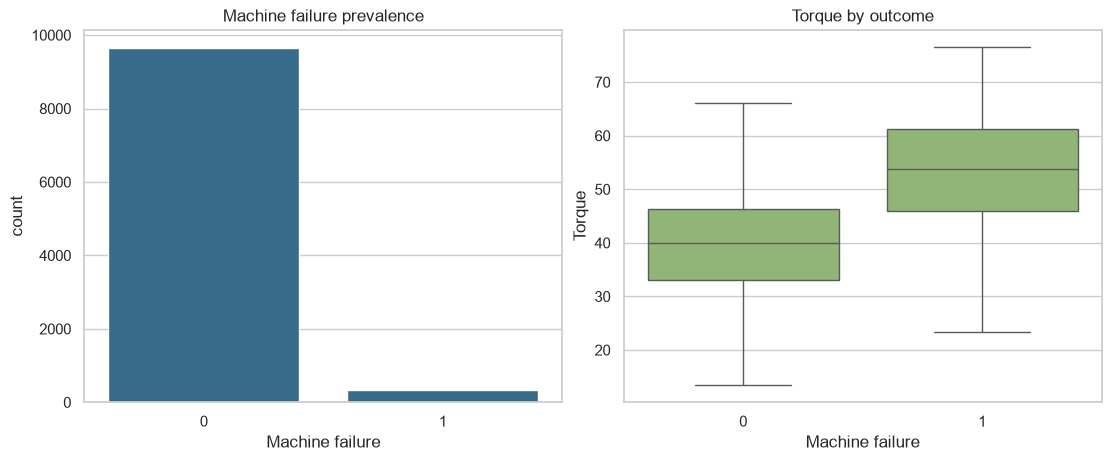

In [2]:
renamed = maintenance.rename(columns={'Air temperature [K]': 'Air temperature', 'Process temperature [K]': 'Process temperature', 'Rotational speed [rpm]': 'Rotational speed', 'Torque [Nm]': 'Torque', 'Tool wear [min]': 'Tool wear'})
figure, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
sns.countplot(data=renamed, x=target, color='#2a6f97', ax=axes[0]); axes[0].set_title('Machine failure prevalence')
sns.boxplot(data=renamed, x=target, y='Torque', color='#90be6d', showfliers=False, ax=axes[1]); axes[1].set_title('Torque by outcome')
plt.show()

## Remove identifiers and leakage columns before splitting

In [3]:
excluded = {'UDI', 'Product ID', 'Failure Type', 'Target', 'Machine failure'}
feature_columns = [column for column in maintenance.columns if column not in excluded]
X = maintenance[feature_columns].copy(); y = maintenance[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.30, stratify=y, random_state=SEED)
categorical = ['Type']; numeric = [column for column in feature_columns if column not in categorical]
preprocessor = ColumnTransformer([('numeric', StandardScaler(), numeric), ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical)])
model = Pipeline([('preprocessor', preprocessor), ('classifier', LogisticRegression(class_weight='balanced', max_iter=2000, random_state=SEED))])
baseline = DummyClassifier(strategy='prior')
model.fit(X_train, y_train); baseline.fit(X_train, y_train)
predictions = model.predict(X_test); probabilities = model.predict_proba(X_test)[:, 1]; baseline_probabilities = baseline.predict_proba(X_test)[:, 1]
metrics = {'rows': len(maintenance), 'failure_share': y.mean(), 'balanced_accuracy': balanced_accuracy_score(y_test, predictions), 'f1': f1_score(y_test, predictions), 'roc_auc': roc_auc_score(y_test, probabilities), 'average_precision': average_precision_score(y_test, probabilities), 'baseline_average_precision': average_precision_score(y_test, baseline_probabilities)}
print(classification_report(y_test, predictions, target_names=['no failure', 'failure'], digits=3))

              precision    recall  f1-score   support

  no failure      0.999     1.000     1.000      2898
     failure      1.000     0.980     0.990       102

    accuracy                          0.999      3000
   macro avg      1.000     0.990     0.995      3000
weighted avg      0.999     0.999     0.999      3000



## Compare ranking metrics and thresholded errors

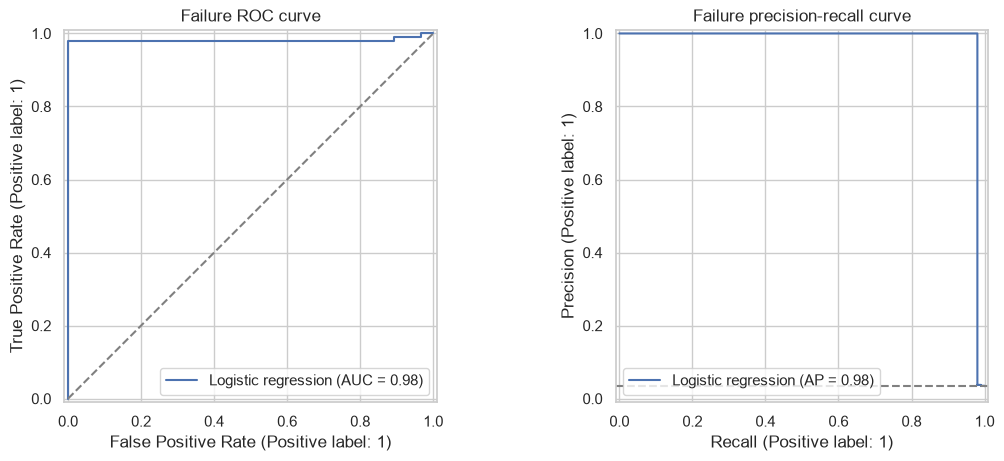

In [4]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
RocCurveDisplay.from_predictions(y_test, probabilities, name='Logistic regression', ax=axes[0]); axes[0].plot([0, 1], [0, 1], '--', color='gray'); axes[0].set_title('Failure ROC curve')
PrecisionRecallDisplay.from_predictions(y_test, probabilities, name='Logistic regression', ax=axes[1]); axes[1].axhline(y_test.mean(), linestyle='--', color='gray'); axes[1].set_title('Failure precision-recall curve')
plt.show()

## Inspect the confusion matrix

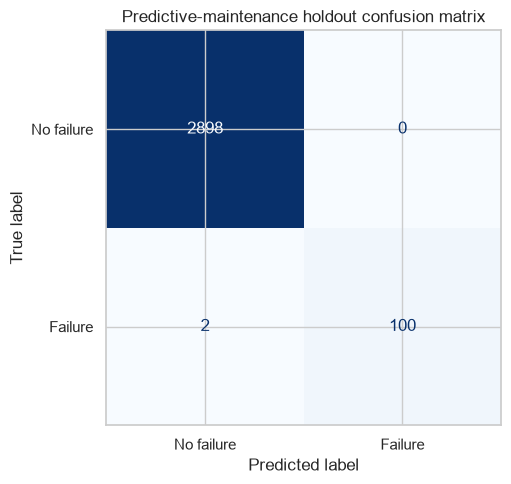

In [5]:
figure, ax = plt.subplots(figsize=(6, 5)); ConfusionMatrixDisplay.from_predictions(y_test, predictions, display_labels=['No failure', 'Failure'], cmap='Blues', colorbar=False, ax=ax)
ax.set_title('Predictive-maintenance holdout confusion matrix'); plt.tight_layout(); plt.show()

## Measure holdout permutation importance

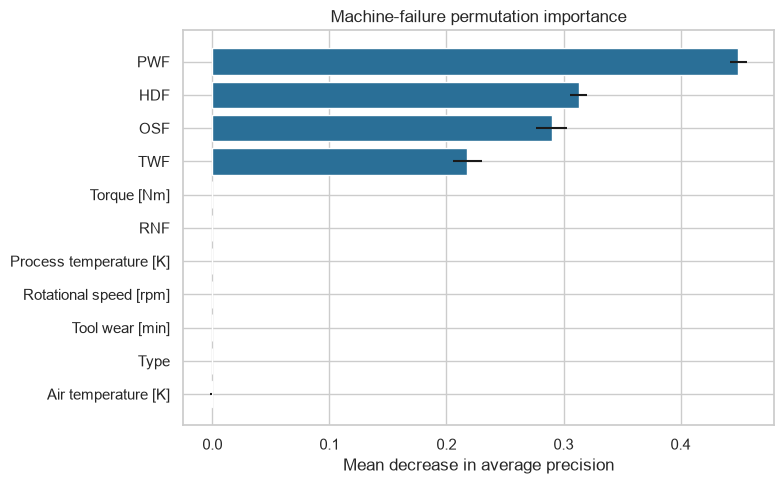

RESULT_JSON={"rows": 10000, "failure_share": 0.0339, "balanced_accuracy": 0.9901960784313726, "f1": 0.9900990099009901, "roc_auc": 0.9817724191125725, "average_precision": 0.9811050046166704, "baseline_average_precision": 0.034, "top_feature": "PWF"}


In [6]:
importance = permutation_importance(model, X_test, y_test, scoring='average_precision', n_repeats=10, random_state=SEED, n_jobs=1)
importance_frame = pd.DataFrame({'feature': feature_columns, 'mean_ap_decrease': importance.importances_mean, 'std': importance.importances_std}).sort_values('mean_ap_decrease')
figure, ax = plt.subplots(figsize=(8, 5)); ax.barh(importance_frame['feature'], importance_frame['mean_ap_decrease'], xerr=importance_frame['std'], color='#2a6f97')
ax.set(title='Machine-failure permutation importance', xlabel='Mean decrease in average precision'); plt.tight_layout(); plt.show()
metrics['top_feature'] = importance_frame.iloc[-1]['feature']; print('RESULT_JSON=' + json.dumps(metrics))

## Limitations

AI4I is a synthetic benchmark, so these scores are not evidence of performance on a real production line. The random holdout does not test time drift, machine-to-machine transfer, or maintenance interventions. Balanced class weights and a 0.5 threshold create a specific false-alarm trade-off; deployment requires cost-based threshold selection, temporal validation, calibrated probabilities, and monitoring.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.